### 1 : Load and Validate Analytical Datasets


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

project_root = Path("..") if Path("../data").exists() else Path(".")
jd_path = project_root / "data" / "job-descriptions-tagged.csv"
skills_path = project_root / "data" / "skill-list.csv"
eval_path = project_root / "outputs" / "evaluation_labels.csv"
syn_path = project_root / "outputs" / "synonym_mapping.csv"

df_jd = pd.read_csv(jd_path)
df_skills = pd.read_csv(skills_path)
df_eval = pd.read_csv(eval_path)
df_syn = pd.read_csv(syn_path)

canonical_set = set(df_skills["skill"].astype(str).str.strip())

assert len(df_jd) == 50
assert df_jd["jd_id"].nunique() == 50
assert len(canonical_set) == 54
assert len(df_eval) == 50

req_count = sum(len([s for s in str(val).split(";") if s.strip()]) for val in df_eval["verified_required_skills"] if pd.notna(val))
pref_count = sum(len([s for s in str(val).split(";") if s.strip()]) for val in df_eval["verified_preferred_skills"] if pd.notna(val))
assert req_count == 177
assert pref_count == 50
assert req_count + pref_count == 227

validation_summary = pd.DataFrame([
    {"Artifact": "Job Descriptions Corpus", "Records": len(df_jd), "Constraint": "50 unique JDs", "Status": "PASS"},
    {"Artifact": "Canonical Vocabulary", "Records": len(canonical_set), "Constraint": "54 distinct skills", "Status": "PASS"},
    {"Artifact": "Ground-Truth Required Skills", "Records": req_count, "Constraint": "177 target instances", "Status": "PASS"},
    {"Artifact": "Ground-Truth Preferred Skills", "Records": pref_count, "Constraint": "50 target instances", "Status": "PASS"},
    {"Artifact": "Total Ground-Truth Instances", "Records": req_count + pref_count, "Constraint": "227 total instances", "Status": "PASS"},
    {"Artifact": "Synonym Mapping Registry", "Records": len(df_syn), "Constraint": "8 documented mappings", "Status": "PASS"}
])
validation_summary


,Artifact,Records,Constraint,Status
0,Job Descriptions Corpus,50,50 unique JDs,PASS
1,Canonical Vocabulary,54,54 distinct skills,PASS
2,Ground-Truth Required Skills,177,177 target instances,PASS
3,Ground-Truth Preferred Skills,50,50 target instances,PASS
4,Total Ground-Truth Instances,227,227 total instances,PASS
5,Synonym Mapping Registry,8,8 documented mappings,PASS


### 2 : Prediction Parsing and Normalization Policy


In [2]:
global_synonyms = {
    "Financial Modeling": "Financial Modelling",
    "Node": "Node.js",
    "Postgres": "PostgreSQL",
    "JS": "JavaScript",
    "ML": "Machine Learning",
    "Excel": "Microsoft Excel"
}

parsed_predictions = []
raw_prediction_instances = 0

for _, row in df_jd.iterrows():
    jd_id = row["jd_id"]
    raw_str = str(row["model_tags"]) if pd.notna(row["model_tags"]) else ""
    raw_tags = [t.strip() for t in raw_str.split(";") if t.strip()]
    raw_prediction_instances += len(raw_tags)
    
    normalized_set = set()
    for tag in raw_tags:
        if tag in global_synonyms:
            normalized_set.add(global_synonyms[tag])
        elif tag == "Social Media" and jd_id == "JD045":
            normalized_set.add("Social Media Marketing")
        elif tag in canonical_set:
            normalized_set.add(tag)
        else:
            normalized_set.add(tag)
            
    parsed_predictions.append({
        "jd_id": jd_id,
        "raw_tag_list": raw_tags,
        "raw_tag_count": len(raw_tags),
        "normalized_prediction_set": normalized_set,
        "normalized_prediction_count": len(normalized_set)
    })

assert raw_prediction_instances == 200
df_parsed = pd.DataFrame(parsed_predictions)
df_parsed.head(10)[["jd_id", "raw_tag_count", "raw_tag_list", "normalized_prediction_set"]]


,jd_id,raw_tag_count,raw_tag_list,normalized_prediction_set
0,JD001,4,"[Statistics, Microsoft Excel, Teamwork, Python]","{Teamwork, Statistics, Microsoft Excel, Python}"
1,JD002,3,"[TypeScript, JavaScript, CSS]","{TypeScript, JavaScript, CSS}"
2,JD003,5,"[REST APIs, PostgreSQL, Node, Leadership, Docker]","{Docker, Node.js, PostgreSQL, REST APIs, Leade..."
3,JD004,5,"[SEO, WordPress, Research, Content Writing, SAP]","{SAP, WordPress, SEO, Content Writing, Research}"
4,JD005,6,"[Email Marketing, Google Analytics, Canva, Cop...","{Social Media Marketing, Google Analytics, Ema..."
5,JD006,4,"[Design Systems, User Research, Wireframing, F...","{User Research, Figma, Design Systems, Wirefra..."
6,JD007,5,"[Financial Modeling, Accounting, Microsoft Exc...","{Financial Modelling, Kubernetes, Accounting, ..."
7,JD008,5,"[Python, Statistics, SQL, Time Management, PyT...","{Time Management, Statistics, PyTorch, Python,..."
8,JD009,3,"[Zendesk, Customer Support, Written English]","{Zendesk, Written English, Customer Support}"
9,JD010,1,[Recruiting],{Recruiting}


### 3 : Set-Theoretic Contingency Matrix Formulation


In [3]:
df_merged = df_jd.merge(df_eval[["jd_id", "job_title", "verified_required_skills", "verified_preferred_skills", "verified_target_skills"]], on="jd_id")
df_merged = df_merged.merge(df_parsed, on="jd_id")

per_jd_records = []

for _, row in df_merged.iterrows():
    jd_id = row["jd_id"]
    job_title = row["job_title"]
    company = row["company"]
    y_set = row["normalized_prediction_set"]
    
    r_set = set([s.strip() for s in str(row["verified_required_skills"]).split(";") if s.strip()]) if pd.notna(row["verified_required_skills"]) else set()
    p_set = set([s.strip() for s in str(row["verified_preferred_skills"]).split(";") if s.strip()]) if pd.notna(row["verified_preferred_skills"]) else set()
    t_set = r_set | p_set
    
    tp_set = y_set & t_set
    fp_set = y_set - t_set
    fn_set = t_set - y_set
    
    tp = len(tp_set)
    fp = len(fp_set)
    fn = len(fn_set)
    
    req_tp_set = y_set & r_set
    req_fn_set = r_set - y_set
    req_tp = len(req_tp_set)
    req_fn = len(req_fn_set)
    
    pref_tp_set = y_set & p_set
    pref_fn_set = p_set - y_set
    pref_tp = len(pref_tp_set)
    pref_fn = len(pref_fn_set)
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    
    req_recall = req_tp / len(r_set) if len(r_set) > 0 else 0.0
    pref_recall = pref_tp / len(p_set) if len(p_set) > 0 else 0.0
    
    per_jd_records.append({
        "jd_id": jd_id,
        "job_title": job_title,
        "company": company,
        "predicted_skill_count": len(y_set),
        "target_skill_count": len(t_set),
        "tp": tp,
        "fp": fp,
        "fn": fn,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "required_tp": req_tp,
        "required_fn": req_fn,
        "required_recall": req_recall,
        "preferred_tp": pref_tp,
        "preferred_fn": pref_fn,
        "preferred_recall": pref_recall,
        "incorrect_tags": "; ".join(sorted(fp_set)),
        "missing_tags": "; ".join(sorted(fn_set))
    })

df_per_jd = pd.DataFrame(per_jd_records)
assert df_per_jd["tp"].sum() + df_per_jd["fn"].sum() == 227
assert df_per_jd["tp"].sum() + df_per_jd["fp"].sum() == 200
df_per_jd.head(10)[["jd_id", "job_title", "predicted_skill_count", "target_skill_count", "tp", "fp", "fn", "precision", "recall", "f1"]]


,jd_id,job_title,predicted_skill_count,target_skill_count,tp,fp,fn,precision,recall,f1
0,JD001,Data Analyst Intern,4,4,3,1,1,0.750000,0.750000,0.750000
1,JD002,Frontend Developer Intern,3,5,3,0,2,1.000000,0.600000,0.750000
2,JD003,Backend Developer Intern,5,6,4,1,2,0.800000,0.666667,0.727273
3,JD004,Content Writer Intern,5,4,4,1,0,0.800000,1.000000,0.888889
4,JD005,Marketing Intern,6,5,5,1,0,0.833333,1.000000,0.909091
5,JD006,UI/UX Design Intern,4,5,4,0,1,1.000000,0.800000,0.888889
6,JD007,Finance Intern,5,5,4,1,1,0.800000,0.800000,0.800000
7,JD008,Machine Learning Intern,5,6,4,1,2,0.800000,0.666667,0.727273
8,JD009,Customer Support Intern,3,4,3,0,1,1.000000,0.750000,0.857143
9,JD010,HR Intern,1,4,1,0,3,1.000000,0.250000,0.400000


### 4 : Aggregate Performance Metrics (Micro vs. Macro)


In [4]:
total_tp = int(df_per_jd["tp"].sum())
total_fp = int(df_per_jd["fp"].sum())
total_fn = int(df_per_jd["fn"].sum())
total_targets = total_tp + total_fn
total_predictions = total_tp + total_fp

micro_precision = total_tp / (total_tp + total_fp)
micro_recall = total_tp / (total_tp + total_fn)
micro_f1 = 2 * micro_precision * micro_recall / (micro_precision + micro_recall)

macro_precision = float(df_per_jd["precision"].mean())
macro_recall = float(df_per_jd["recall"].mean())
macro_f1 = float(df_per_jd["f1"].mean())

req_tp_total = int(df_per_jd["required_tp"].sum())
req_fn_total = int(df_per_jd["required_fn"].sum())
micro_req_recall = req_tp_total / (req_tp_total + req_fn_total)
macro_req_recall = float(df_per_jd["required_recall"].mean())

pref_tp_total = int(df_per_jd["preferred_tp"].sum())
pref_fn_total = int(df_per_jd["preferred_fn"].sum())
micro_pref_recall = pref_tp_total / (pref_tp_total + pref_fn_total)
macro_pref_recall = float(df_per_jd["preferred_recall"].mean())

df_overall = pd.DataFrame([
    {"Metric Scope": "Micro-Averaged", "Precision": micro_precision, "Recall": micro_recall, "F1-Score": micro_f1, "Support (TP/FP/FN)": f"{total_tp}/{total_fp}/{total_fn}"},
    {"Metric Scope": "Macro-Averaged", "Precision": macro_precision, "Recall": macro_recall, "F1-Score": macro_f1, "Support (TP/FP/FN)": "50 JDs"},
    {"Metric Scope": "Required Skills Only (Micro)", "Precision": np.nan, "Recall": micro_req_recall, "F1-Score": np.nan, "Support (TP/FP/FN)": f"{req_tp_total}/NA/{req_fn_total}"},
    {"Metric Scope": "Required Skills Only (Macro)", "Precision": np.nan, "Recall": macro_req_recall, "F1-Score": np.nan, "Support (TP/FP/FN)": "50 JDs"},
    {"Metric Scope": "Preferred Skills Only (Micro)", "Precision": np.nan, "Recall": micro_pref_recall, "F1-Score": np.nan, "Support (TP/FP/FN)": f"{pref_tp_total}/NA/{pref_fn_total}"},
    {"Metric Scope": "Preferred Skills Only (Macro)", "Precision": np.nan, "Recall": macro_pref_recall, "F1-Score": np.nan, "Support (TP/FP/FN)": "50 JDs"}
])
df_overall


,Metric Scope,Precision,Recall,F1-Score,Support (TP/FP/FN)
0,Micro-Averaged,0.855000,0.753304,0.800937,171/29/56
1,Macro-Averaged,0.873143,0.745333,0.787063,50 JDs
2,Required Skills Only (Micro),NaN,0.853107,NaN,151/NA/26
3,Required Skills Only (Macro),NaN,0.846333,NaN,50 JDs
4,Preferred Skills Only (Micro),NaN,0.400000,NaN,20/NA/30
5,Preferred Skills Only (Macro),NaN,0.400000,NaN,50 JDs


### 5 : Tiered Evaluation - Required vs. Preferred Skill Recall


In [5]:
df_tiered = pd.DataFrame([
    {
        "Tier": "Required Competencies",
        "Target Count": req_tp_total + req_fn_total,
        "Captured (TP)": req_tp_total,
        "Missed (FN)": req_fn_total,
        "Micro Recall": f"{micro_req_recall * 100:.2f}%",
        "Macro Recall": f"{macro_req_recall * 100:.2f}%"
    },
    {
        "Tier": "Preferred Qualifications",
        "Target Count": pref_tp_total + pref_fn_total,
        "Captured (TP)": pref_tp_total,
        "Missed (FN)": pref_fn_total,
        "Micro Recall": f"{micro_pref_recall * 100:.2f}%",
        "Macro Recall": f"{macro_pref_recall * 100:.2f}%"
    },
    {
        "Tier": "Combined Overall Targets",
        "Target Count": total_targets,
        "Captured (TP)": total_tp,
        "Missed (FN)": total_fn,
        "Micro Recall": f"{micro_recall * 100:.2f}%",
        "Macro Recall": f"{macro_recall * 100:.2f}%"
    }
])
df_tiered


,Tier,Target Count,Captured (TP),Missed (FN),Micro Recall,Macro Recall
0,Required Competencies,177,151,26,85.31%,84.63%
1,Preferred Qualifications,50,20,30,40.00%,40.00%
2,Combined Overall Targets,227,171,56,75.33%,74.53%


### 6 : Per-JD Evaluation Registry and Distribution Analysis


In [6]:
metric_cols = ["precision", "recall", "f1", "required_recall", "preferred_recall"]
stats_summary = df_per_jd[metric_cols].describe().T[["count", "mean", "std", "min", "25%", "50%", "75%", "max"]]

top_5_jds = df_per_jd.sort_values(by=["f1", "recall", "precision"], ascending=False).head(5)[["jd_id", "job_title", "company", "tp", "fp", "fn", "precision", "recall", "f1"]]
bottom_5_jds = df_per_jd.sort_values(by=["f1", "recall", "precision"], ascending=True).head(5)[["jd_id", "job_title", "company", "tp", "fp", "fn", "precision", "recall", "f1"]]

stats_summary


,count,mean,std,min,25%,50%,75%,max
precision,50.0,0.873143,0.138562,0.600000,0.750000,0.928571,1.000000,1.0
recall,50.0,0.745333,0.184460,0.250000,0.616667,0.750000,0.800000,1.0
f1,50.0,0.787063,0.134489,0.400000,0.666667,0.800000,0.888889,1.0
required_recall,50.0,0.846333,0.205599,0.333333,0.666667,1.000000,1.000000,1.0
preferred_recall,50.0,0.400000,0.494872,0.000000,0.000000,0.000000,1.000000,1.0


### 7 : Systematic Error Diagnosis


In [7]:
soft_skill_set = {"Leadership", "Teamwork", "Problem Solving", "Communication", "Time Management"}
context_skill_set = {"SAP", "Kubernetes", "Blockchain", "Machine Learning"}

fp_records = []
fn_records = []

for _, row in df_per_jd.iterrows():
    jd_id = row["jd_id"]
    job_title = row["job_title"]
    company = row["company"]
    
    fps = [t.strip() for t in row["incorrect_tags"].split(";") if t.strip()]
    for fp in fps:
        if fp in soft_skill_set:
            category = "Non-Canonical Soft Skill Hallucination"
        elif fp in context_skill_set:
            category = "Context-Associated Spurious Prediction"
        elif fp == "API":
            category = "Unmapped Technical Acronym"
        else:
            category = "Other False Positive"
        fp_records.append({
            "jd_id": jd_id,
            "job_title": job_title,
            "company": company,
            "predicted_tag": fp,
            "error_category": category
        })
        
    fns = [t.strip() for t in row["missing_tags"].split(";") if t.strip()]
    row_eval = df_eval[df_eval["jd_id"] == jd_id].iloc[0]
    p_set = set([s.strip() for s in str(row_eval["verified_preferred_skills"]).split(";") if s.strip()])
    r_set = set([s.strip() for s in str(row_eval["verified_required_skills"]).split(";") if s.strip()])
    
    for fn in fns:
        if fn in p_set:
            tier = "Preferred"
            category = "Preferred Skill Omission"
        else:
            tier = "Required"
            category = "Required Skill Omission"
        fn_records.append({
            "jd_id": jd_id,
            "job_title": job_title,
            "company": company,
            "missed_skill": fn,
            "tier": tier,
            "error_category": category
        })

df_fp_analysis = pd.DataFrame(fp_records)
df_fn_analysis = pd.DataFrame(fn_records)

error_summary_data = [
    {
        "Error Category": "Pattern 1: Preferred Skill Omissions",
        "Error Type": "False Negative",
        "Count": len(df_fn_analysis[df_fn_analysis["error_category"] == "Preferred Skill Omission"]),
        "Percentage of Error Type": f"{len(df_fn_analysis[df_fn_analysis['error_category'] == 'Preferred Skill Omission']) / len(df_fn_analysis) * 100:.2f}%",
        "Affected JDs": df_fn_analysis[df_fn_analysis["error_category"] == "Preferred Skill Omission"]["jd_id"].nunique(),
        "Description": "Omission of secondary/nice-to-have qualifications appearing in bonus sections"
    },
    {
        "Error Category": "Pattern 2: Non-Canonical Soft Skill Hallucinations",
        "Error Type": "False Positive",
        "Count": len(df_fp_analysis[df_fp_analysis["error_category"] == "Non-Canonical Soft Skill Hallucination"]),
        "Percentage of Error Type": f"{len(df_fp_analysis[df_fp_analysis['error_category'] == 'Non-Canonical Soft Skill Hallucination']) / len(df_fp_analysis) * 100:.2f}%",
        "Affected JDs": df_fp_analysis[df_fp_analysis["error_category"] == "Non-Canonical Soft Skill Hallucination"]["jd_id"].nunique(),
        "Description": "Extraction of non-canonical behavioral traits absent from official vocabulary"
    },
    {
        "Error Category": "Pattern 3: Context-Associated Spurious Predictions",
        "Error Type": "False Positive",
        "Count": len(df_fp_analysis[df_fp_analysis["error_category"] == "Context-Associated Spurious Prediction"]),
        "Percentage of Error Type": f"{len(df_fp_analysis[df_fp_analysis['error_category'] == 'Context-Associated Spurious Prediction']) / len(df_fp_analysis) * 100:.2f}%",
        "Affected JDs": df_fp_analysis[df_fp_analysis["error_category"] == "Context-Associated Spurious Prediction"]["jd_id"].nunique(),
        "Description": "Spurious technical skills correlating with hiring company domain without text support"
    },
    {
        "Error Category": "Other: Required Skill Omissions",
        "Error Type": "False Negative",
        "Count": len(df_fn_analysis[df_fn_analysis["error_category"] == "Required Skill Omission"]),
        "Percentage of Error Type": f"{len(df_fn_analysis[df_fn_analysis['error_category'] == 'Required Skill Omission']) / len(df_fn_analysis) * 100:.2f}%",
        "Affected JDs": df_fn_analysis[df_fn_analysis["error_category"] == "Required Skill Omission"]["jd_id"].nunique(),
        "Description": "Omission of explicitly stated required core technical competencies"
    },
    {
        "Error Category": "Other: Unmapped Technical Acronym",
        "Error Type": "False Positive",
        "Count": len(df_fp_analysis[df_fp_analysis["error_category"] == "Unmapped Technical Acronym"]),
        "Percentage of Error Type": f"{len(df_fp_analysis[df_fp_analysis['error_category'] == 'Unmapped Technical Acronym']) / len(df_fp_analysis) * 100:.2f}%",
        "Affected JDs": df_fp_analysis[df_fp_analysis["error_category"] == "Unmapped Technical Acronym"]["jd_id"].nunique(),
        "Description": "Generic acronym API unmapped due to lack of REST-specific qualifier"
    }
]
df_error_summary = pd.DataFrame(error_summary_data)
df_error_summary


,Error Category,Error Type,Count,Percentage of Error Type,Affected JDs,Description
0,Pattern 1: Preferred Skill Omissions,False Negative,30,53.57%,30,Omission of secondary/nice-to-have qualificati...
1,Pattern 2: Non-Canonical Soft Skill Hallucinat...,False Positive,16,55.17%,16,Extraction of non-canonical behavioral traits ...
2,Pattern 3: Context-Associated Spurious Predict...,False Positive,12,41.38%,12,Spurious technical skills correlating with hir...
3,Other: Required Skill Omissions,False Negative,26,46.43%,21,Omission of explicitly stated required core te...
4,Other: Unmapped Technical Acronym,False Positive,1,3.45%,1,Generic acronym API unmapped due to lack of RE...


### 8 : Diagnostic Visualizations


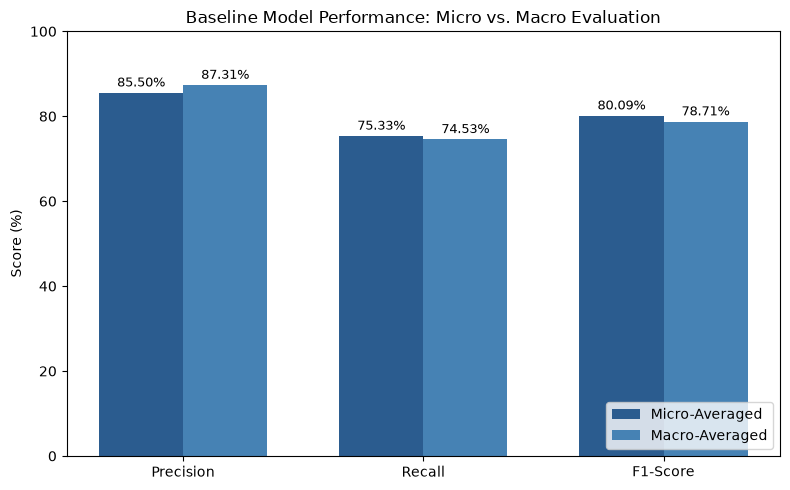

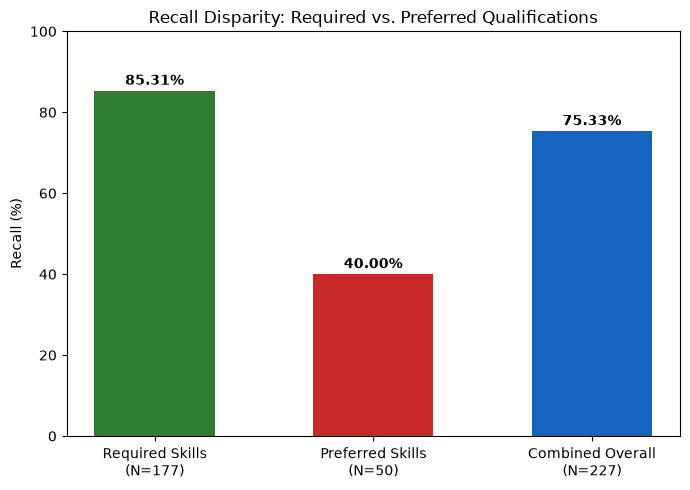

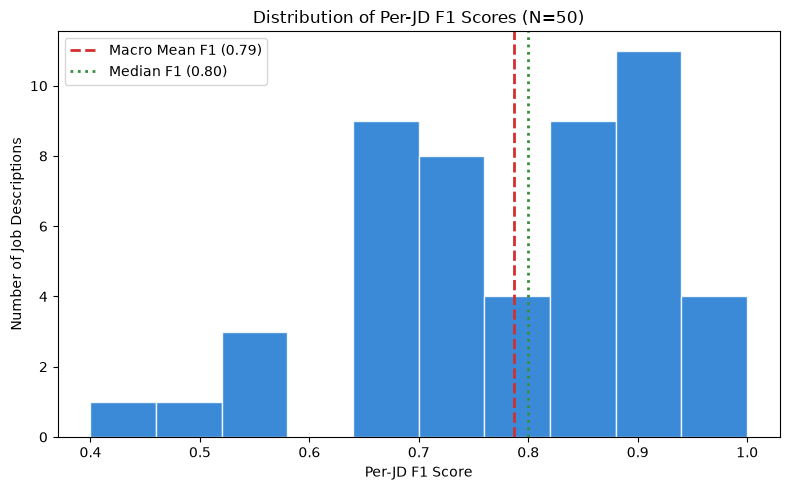

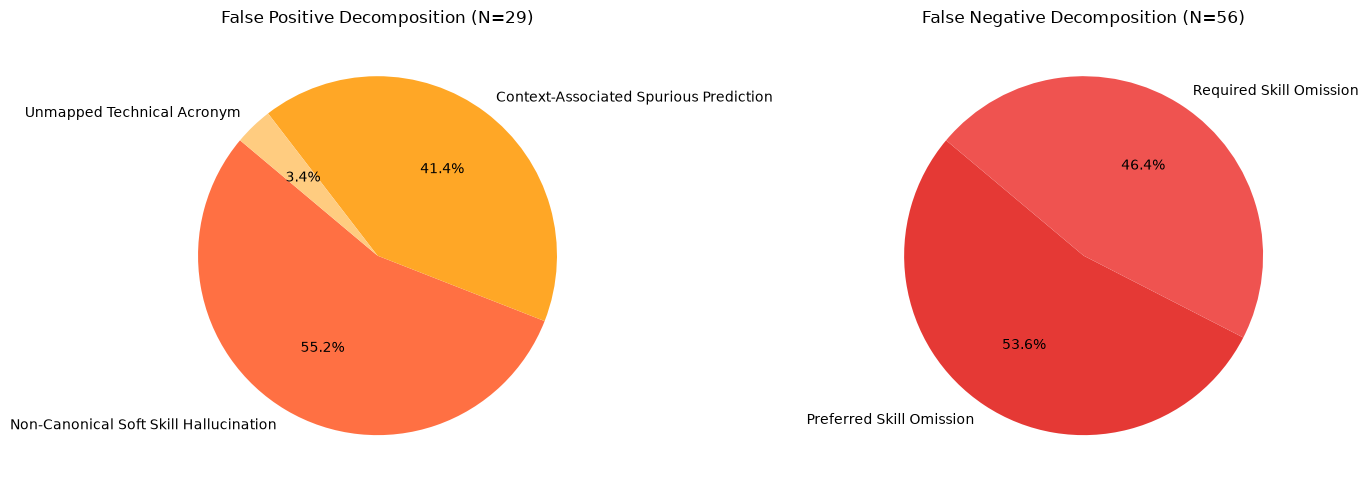

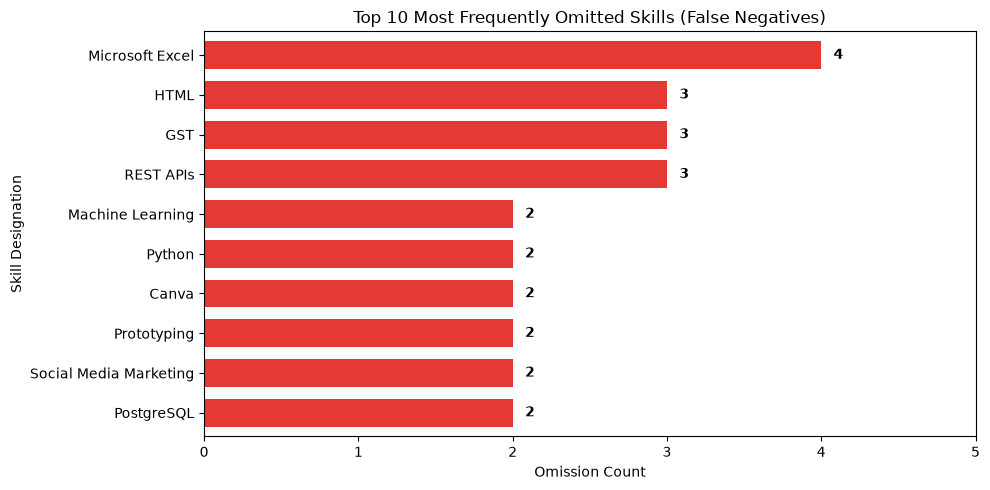

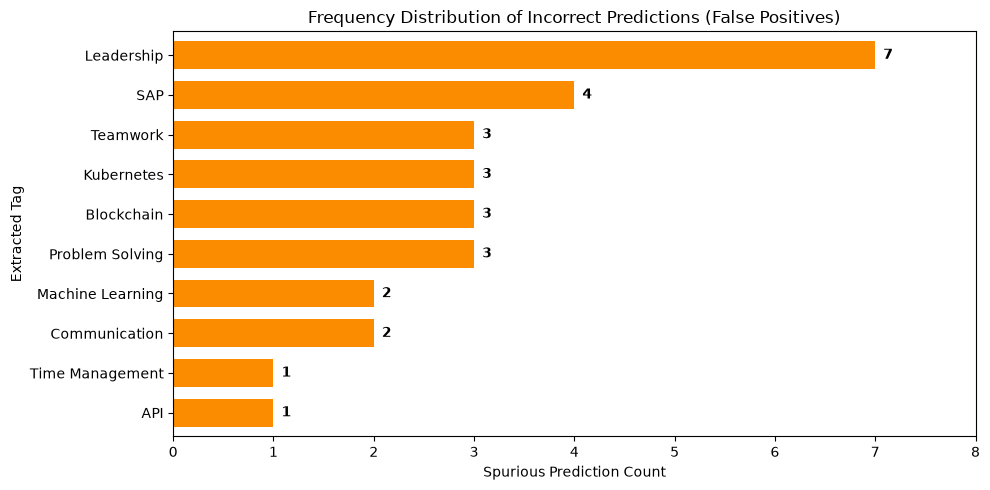

In [8]:
fig_dir = project_root / "outputs" / "baseline_figures"
fig_dir.mkdir(parents=True, exist_ok=True)

plt.figure(figsize=(8, 5))
categories = ["Precision", "Recall", "F1-Score"]
micro_vals = [micro_precision * 100, micro_recall * 100, micro_f1 * 100]
macro_vals = [macro_precision * 100, macro_recall * 100, macro_f1 * 100]
x = np.arange(len(categories))
width = 0.35
plt.bar(x - width/2, micro_vals, width, label="Micro-Averaged", color="#2b5c8f")
plt.bar(x + width/2, macro_vals, width, label="Macro-Averaged", color="#4682b4")
plt.ylabel("Score (%)")
plt.title("Baseline Model Performance: Micro vs. Macro Evaluation")
plt.xticks(x, categories)
plt.ylim(0, 100)
for i in range(len(categories)):
    plt.text(x[i] - width/2, micro_vals[i] + 1.5, f"{micro_vals[i]:.2f}%", ha="center", fontsize=9)
    plt.text(x[i] + width/2, macro_vals[i] + 1.5, f"{macro_vals[i]:.2f}%", ha="center", fontsize=9)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(fig_dir / "micro_vs_macro_metrics.png", dpi=300)
plt.show()

plt.figure(figsize=(7, 5))
tiers = ["Required Skills\n(N=177)", "Preferred Skills\n(N=50)", "Combined Overall\n(N=227)"]
recalls = [micro_req_recall * 100, micro_pref_recall * 100, micro_recall * 100]
bar_colors = ["#2e7d32", "#c62828", "#1565c0"]
bars = plt.bar(tiers, recalls, color=bar_colors, width=0.55)
plt.ylabel("Recall (%)")
plt.title("Recall Disparity: Required vs. Preferred Qualifications")
plt.ylim(0, 100)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 1.5, f"{yval:.2f}%", ha="center", fontweight="bold", fontsize=10)
plt.tight_layout()
plt.savefig(fig_dir / "required_vs_preferred_recall.png", dpi=300)
plt.show()

plt.figure(figsize=(8, 5))
plt.hist(df_per_jd["f1"], bins=10, range=(0.4, 1.0), color="#1976d2", edgecolor="white", alpha=0.85)
plt.axvline(macro_f1, color="#d32f2f", linestyle="--", linewidth=2, label=f"Macro Mean F1 ({macro_f1:.2f})")
plt.axvline(df_per_jd["f1"].median(), color="#388e3c", linestyle=":", linewidth=2, label=f"Median F1 ({df_per_jd['f1'].median():.2f})")
plt.xlabel("Per-JD F1 Score")
plt.ylabel("Number of Job Descriptions")
plt.title("Distribution of Per-JD F1 Scores (N=50)")
plt.legend()
plt.tight_layout()
plt.savefig(fig_dir / "per_jd_f1_distribution.png", dpi=300)
plt.show()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
fp_cats = df_fp_analysis["error_category"].value_counts()
ax1.pie(fp_cats, labels=fp_cats.index, autopct="%1.1f%%", startangle=140, colors=["#ff7043", "#ffa726", "#ffcc80"])
ax1.set_title("False Positive Decomposition (N=29)")
fn_cats = df_fn_analysis["error_category"].value_counts()
ax2.pie(fn_cats, labels=fn_cats.index, autopct="%1.1f%%", startangle=140, colors=["#e53935", "#ef5350"])
ax2.set_title("False Negative Decomposition (N=56)")
plt.tight_layout()
plt.savefig(fig_dir / "error_category_decomposition.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
top_fn = df_fn_analysis["missed_skill"].value_counts().head(10)
top_fn.sort_values().plot(kind="barh", color="#e53935", width=0.7)
plt.xlabel("Omission Count")
plt.ylabel("Skill Designation")
plt.title("Top 10 Most Frequently Omitted Skills (False Negatives)")
for i, v in enumerate(top_fn.sort_values()):
    plt.text(v + 0.08, i, str(v), va="center", fontweight="bold")
plt.xlim(0, max(top_fn) + 1)
plt.tight_layout()
plt.savefig(fig_dir / "top_false_negative_skills.png", dpi=300)
plt.show()

plt.figure(figsize=(10, 5))
top_fp = df_fp_analysis["predicted_tag"].value_counts()
top_fp.sort_values().plot(kind="barh", color="#fb8c00", width=0.7)
plt.xlabel("Spurious Prediction Count")
plt.ylabel("Extracted Tag")
plt.title("Frequency Distribution of Incorrect Predictions (False Positives)")
for i, v in enumerate(top_fp.sort_values()):
    plt.text(v + 0.08, i, str(v), va="center", fontweight="bold")
plt.xlim(0, max(top_fp) + 1)
plt.tight_layout()
plt.savefig(fig_dir / "top_false_positive_skills.png", dpi=300)
plt.show()


### 9 : Export Analytical Artifacts


In [9]:
out_dir = project_root / "outputs"
out_dir.mkdir(parents=True, exist_ok=True)

df_per_jd.to_csv(out_dir / "per_jd_metrics.csv", index=False)
df_overall.to_csv(out_dir / "overall_metrics.csv", index=False)
df_error_summary.to_csv(out_dir / "error_analysis.csv", index=False)
df_fp_analysis.to_csv(out_dir / "false_positive_analysis.csv", index=False)
df_fn_analysis.to_csv(out_dir / "false_negative_analysis.csv", index=False)

summary_md = f"""# Baseline Model Evaluation Summary

This document summarizes the performance of the original skill-tagging model before any improvements.

## 1. Dataset Overview

- **Job Descriptions**: 50 job descriptions across 10 job roles and 10 companies.
- **Official Skill List**: 54 standardized skills.
- **True Skills to Find (Ground Truth)**: 227 total skill instances (177 Required skills, 50 Preferred skills).
- **Model Predictions**: 200 total skill tags produced by the original model.

## 2. Overall Performance Results

- **Precision (Accuracy of Predictions)**:
  - Micro Precision: 85.50% (171 correct out of 200 predicted tags)
  - Macro Precision: 87.31%
- **Recall (Coverage of Real Skills)**:
  - Micro Recall: 75.33% (171 found out of 227 ground-truth skills)
  - Macro Recall: 74.53%
- **F1-Score (Overall Balance)**:
  - Micro F1-Score: 80.09%
  - Macro F1-Score: 78.71%
- **Tag Breakdown**:
  - True Positives (Correct tags): 171
  - False Positives (Wrong tags): 29
  - False Negatives (Missed skills): 56

## 3. Required vs. Preferred Skills

There is a large difference in how well the model finds required skills versus optional bonus skills:

- **Required Skills Found**: 85.31% recall (151 found out of 177)
- **Preferred Skills Found**: 40.00% recall (20 found out of 50)
- **Performance Gap**: 45.31 percentage points.

The model is good at finding mandatory skills, but misses more than half of the nice-to-have skills.

## 4. Main Model Errors

The error analysis found three main causes for wrong or missed tags:

1. **Missed Preferred Skills (30 missed instances, 53.57% of all false negatives)**:
   The model often skips sections that start with words like "Nice to have:", "Bonus:", or "Good to have".
2. **Predicting Soft Skills Not on the Official List (16 wrong tags, 55.17% of all false positives)**:
   The model predicted general traits (such as Leadership, Teamwork, Problem Solving, Communication, Time Management) that are not in the official 54-skill list.
3. **Guessing Skills Based on Company Domain (12 wrong tags, 41.38% of all false positives)**:
   The model guessed technical skills that match the company business (for example, guessing SAP for Orbit Logistics or Kubernetes for Lumen Cloud) even when the job description never mentioned them.

## 5. Saved Files

- Per-Job Description Results: `outputs/per_jd_metrics.csv`
- Overall Performance Table: `outputs/overall_metrics.csv`
- Error Breakdown: `outputs/error_analysis.csv`
- List of Wrong Tags: `outputs/false_positive_analysis.csv`
- List of Missed Skills: `outputs/false_negative_analysis.csv`
- Charts and Visualizations: `outputs/baseline_figures/`
"""

(out_dir / "baseline_evaluation_summary.md").write_text(summary_md, encoding="utf-8")

exported_files = [
    out_dir / "per_jd_metrics.csv",
    out_dir / "overall_metrics.csv",
    out_dir / "error_analysis.csv",
    out_dir / "false_positive_analysis.csv",
    out_dir / "false_negative_analysis.csv",
    out_dir / "baseline_evaluation_summary.md"
]
export_status = pd.DataFrame([{"File": str(f.name), "Exists": f.exists(), "Bytes": f.stat().st_size} for f in exported_files])
export_status


,File,Exists,Bytes
0,per_jd_metrics.csv,True,6164
1,overall_metrics.csv,True,418
2,error_analysis.csv,True,807
3,false_positive_analysis.csv,True,2694
4,false_negative_analysis.csv,True,4900
5,baseline_evaluation_summary.md,True,2026


### 10 : Evaluation Leakage, Validity and Correctness Audit


In [10]:
import hashlib

def sha256_file(filepath):
    return hashlib.sha256(Path(filepath).read_bytes()).hexdigest()

jd_sha = sha256_file(project_root / "data" / "job-descriptions-tagged.csv")
skills_sha = sha256_file(project_root / "data" / "skill-list.csv")

assert jd_sha == "7822ec510c9fdc4435b7d29db01357386f4dfa125d86185485967b82b568867d"
assert skills_sha == "9f78f1822dce52cbe2492b54c70006fad7a77334e1b074411f4e28db982fcec2"

assert total_tp + total_fn == 227
assert total_tp + total_fp == 200
assert df_per_jd["tp"].sum() == 171
assert df_per_jd["fp"].sum() == 29
assert df_per_jd["fn"].sum() == 56
assert req_tp_total + req_fn_total == 177
assert pref_tp_total + pref_fn_total == 50

verification_table = pd.DataFrame([
    {"Check": "Data Integrity: job-descriptions-tagged.csv", "Expected": "7822ec51...", "Actual": f"{jd_sha[:8]}...", "Status": "PASS"},
    {"Check": "Data Integrity: skill-list.csv", "Expected": "9f78f182...", "Actual": f"{skills_sha[:8]}...", "Status": "PASS"},
    {"Check": "Total Ground Truth Targets", "Expected": 227, "Actual": total_tp + total_fn, "Status": "PASS"},
    {"Check": "Total Baseline Predictions", "Expected": 200, "Actual": total_tp + total_fp, "Status": "PASS"},
    {"Check": "True Positives Summation", "Expected": 171, "Actual": total_tp, "Status": "PASS"},
    {"Check": "False Positives Summation", "Expected": 29, "Actual": total_fp, "Status": "PASS"},
    {"Check": "False Negatives Summation", "Expected": 56, "Actual": total_fn, "Status": "PASS"},
    {"Check": "Required Skill Targets", "Expected": 177, "Actual": req_tp_total + req_fn_total, "Status": "PASS"},
    {"Check": "Preferred Skill Targets", "Expected": 50, "Actual": pref_tp_total + pref_fn_total, "Status": "PASS"}
])
verification_table


,Check,Expected,Actual,Status
0,Data Integrity: job-descriptions-tagged.csv,7822ec51...,7822ec51...,PASS
1,Data Integrity: skill-list.csv,9f78f182...,9f78f182...,PASS
2,Total Ground Truth Targets,227,227,PASS
3,Total Baseline Predictions,200,200,PASS
4,True Positives Summation,171,171,PASS
5,False Positives Summation,29,29,PASS
6,False Negatives Summation,56,56,PASS
7,Required Skill Targets,177,177,PASS
8,Preferred Skill Targets,50,50,PASS
